# 0a_06 From Events to Random Variables: Putting a Number on Every Outcome

**Learning objectives**
- Define a **random variable** as a rule that attaches a **number** to each outcome, and build its **probability table** (PMF).
- Compute the **expected value** (the long-run average), the **variance** and the **standard deviation** from a table.
- Use two key rules: **linearity of expectation** $E[aX+b]=aE[X]+b$ and the **additivity of variances** for independent variables.
- See, by simulation, that the average of many repetitions settles at the expected value.

**Prerequisites:** [0a_05 Probability trees, total probability and a first look at Bayes](0a_05_trees_total_probability.ipynb). This lesson leads directly into Module 00 ([00_01 Random variables](../../module_00_foundations/notebooks/00_01_random_variables.ipynb) and [00_02 Expectation and moments](../../module_00_foundations/notebooks/00_02_expectation_moments.ipynb)).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, itertools

## 2. Prerequisite recap

- An **outcome** is one possible result, an **event** is a set of outcomes, and $P(\text{event})$ is its probability (0a_01).
- Probabilities of mutually exclusive events add; all outcome probabilities add to 1.
- For equally likely outcomes $P(A)=|A|/|S|$; counting tools (0a_02) and conditional probability (0a_04) help compute $P(A)$.
- An **average** of numbers $x_1,\dots,x_n$ is $\frac1n\sum x_i$.

## 3. Intuition and story

So far we asked about *events*: "the sum is 7", "the email is spam". Often the interesting quantity is a **number**: the sum of two dice, the number of orders in an hour, the prize of a raffle ticket, the profit of a game. A **random variable** is simply a rule that gives each outcome a number. Roll two dice and let $X$ be the sum: the outcome $(3,4)$ gives $X=7$, the outcome $(6,6)$ gives $X=12$.

Once outcomes have numbers we can ask for two summaries that matter in practice:

- the **expected value** $E[X]$: *where* the numbers are centred, the average you would see over very many repetitions;
- the **variance** $\mathrm{Var}(X)$ and standard deviation: *how spread out* the numbers are, which tells you how risky a single repetition is.

The probability table of a random variable (the **PMF**) is the object that every distribution in this book describes: the Binomial, the Poisson, the Normal are all tables or curves of this kind for particular experiments.

## 4. Formal definitions

| Term | Definition | Example |
|---|---|---|
| **Random variable** $X$ | a rule assigning a number $X(\omega)$ to each outcome $\omega$ | $X$ = sum of two dice |
| **Support** | the set of values $X$ can take | $\{2,3,\dots,12\}$ |
| **PMF** (probability mass function) | $p(x)=P(X=x)$; all $p(x)\ge0$ and $\sum_xp(x)=1$ | $p(7)=\tfrac6{36}$ |
| **CDF** | $F(x)=P(X\le x)=\sum_{t\le x}p(t)$ | $F(4)=\tfrac6{36}$ |
| **Expected value** | $E[X]=\mu=\sum_xx\,p(x)$ | $E[X]=7$ |
| **Variance** | $\mathrm{Var}(X)=\sigma^2=E[(X-\mu)^2]=\sum_x(x-\mu)^2p(x)$ | $\tfrac{35}6$ |
| **Standard deviation** | $\sigma=\sqrt{\mathrm{Var}(X)}$ (same units as $X$) | $2.42$ |
| **Function of $X$** | $E[g(X)]=\sum_xg(x)\,p(x)$ | $E[X^2]=\sum x^2p(x)$ |

**Rules.** For constants $a,b$: $E[aX+b]=aE[X]+b$ and $\mathrm{Var}(aX+b)=a^2\mathrm{Var}(X)$. For any $X,Y$: $E[X+Y]=E[X]+E[Y]$. For **independent** $X,Y$: $\mathrm{Var}(X+Y)=\mathrm{Var}(X)+\mathrm{Var}(Y)$.

## 5. Derivations

### 5.1 The PMF from outcomes
$P(X=x)$ is the probability of the event $\{\omega:X(\omega)=x\}$, the set of outcomes that give the number $x$. For two dice and $X=$ sum, $P(X=7)=|\{(1,6),(2,5),\dots,(6,1)\}|/36=6/36$. **In plain words.** To build the table, go through each value and add up the probabilities of the outcomes that produce it (0a_01 and 0a_02).

### 5.2 Expected value is a weighted average
If $n$ repetitions give the value $x$ in a fraction $p(x)$ of the cases, their average is $\sum_xx\cdot p(x)$. That is the definition of $E[X]$. **In plain words.** Weight every value by how often it happens. For a fair die $E[X]=\tfrac16(1+2+\cdots+6)=3.5$, a value the die never shows: the expected value need not be a possible outcome.

### 5.3 Linearity: $E[aX+b]=aE[X]+b$ and $E[X+Y]=E[X]+E[Y]$
$E[aX+b]=\sum(ax+b)p(x)=a\sum xp(x)+b\sum p(x)=aE[X]+b$. For the sum, $\sum_{x,y}(x+y)p(x,y)=\sum xp(x)+\sum yp(y)$ using the marginals. No independence is needed. **In plain words.** Averages add: the average of a sum is the sum of the averages, even when the parts are dependent. For two dice $E[X+Y]=3.5+3.5=7$.

### 5.4 The variance shortcut
$\mathrm{Var}(X)=E[(X-\mu)^2]=E[X^2]-2\mu E[X]+\mu^2=E[X^2]-\mu^2$. **In plain words.** "Mean of the squares minus the square of the mean": often quicker than subtracting $\mu$ from every value. Check for a fair die: $E[X^2]=\tfrac{91}6=15.17$, $\mu^2=12.25$, variance $=2.917=\tfrac{35}{12}$.

### 5.5 Variance of sums and of $aX+b$
$\mathrm{Var}(aX+b)=E[(aX+b-a\mu-b)^2]=a^2E[(X-\mu)^2]=a^2\mathrm{Var}(X)$: shifting does nothing to the spread and scaling by $a$ scales the SD by $|a|$. For independent $X,Y$ the cross term $2E[(X-\mu_X)(Y-\mu_Y)]$ vanishes, leaving $\mathrm{Var}(X+Y)=\mathrm{Var}(X)+\mathrm{Var}(Y)$. For $n$ independent identical variables the SD of the **sum** grows like $\sqrt n$ and the SD of the **average** shrinks like $1/\sqrt n$. **In plain words.** Randomness partly cancels: ten dice are not ten times as risky as one, only $\sqrt{10}$ times.

### 5.6 The long-run average (preview of the law of large numbers)
The running average of $n$ independent repetitions has mean $\mu$ and variance $\sigma^2/n$, which shrinks to 0, so the average settles at $\mu$ (05_01 gives the theorem and the speed).

## 6. Properties and relationships

- **Mean tells the centre, variance the risk:** two games can have the same expected value and very different spreads (7.3).
- **Units:** $\mu$ and $\sigma$ are in the units of $X$; the variance is in squared units, so quote the SD.
- **$E[g(X)]\ne g(E[X])$ in general:** $E[X^2]\ge(E[X])^2$ (the variance is non-negative).
- **A random variable is a bridge to everything that follows:** Module 00 formalises PMFs, PDFs, CDFs and moments; Module 01 gives named PMFs (Bernoulli, Binomial, Geometric, Poisson); Module 02 turns sums into integrals for continuous variables.
- **Events are random variables too:** the **indicator** $\mathbf 1_A$ equals 1 if $A$ happens and 0 otherwise, so $E[\mathbf 1_A]=P(A)$: probabilities are expected values.

## 7. 2D visuals

### 7.1 The PMF of the sum of two dice
The probability table of $X$ = sum of two dice, from counting the diagonals of the 36-outcome grid. The orange line marks the mean 7 and the band is $\pm1$ standard deviation.

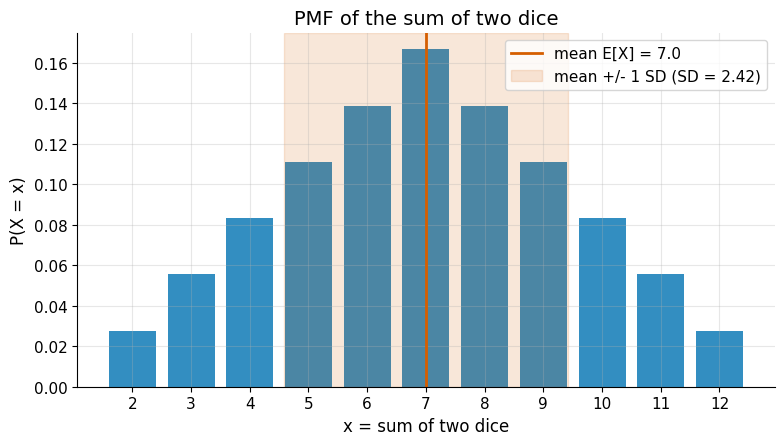

E[X] = 7.0000, Var(X) = 5.8333 (= 35/6 = 5.8333), SD = 2.4152


In [2]:
S = list(itertools.product(range(1, 7), range(1, 7)))
xs = np.arange(2, 13)
pmf = np.array([sum(1 for r, b in S if r + b == x) / 36 for x in xs])
mean_x = np.sum(xs * pmf); var_x = np.sum((xs - mean_x) ** 2 * pmf); sd_x = np.sqrt(var_x)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(xs, pmf, color=MAIN, alpha=0.8); ax.axvline(mean_x, color=HIGHLIGHT, linewidth=2, label=f"mean E[X] = {mean_x:.1f}")
ax.axvspan(mean_x - sd_x, mean_x + sd_x, color=HIGHLIGHT, alpha=0.15, label=f"mean +/- 1 SD (SD = {sd_x:.2f})")
ax.set_xlabel("x = sum of two dice"); ax.set_ylabel("P(X = x)"); ax.set_title("PMF of the sum of two dice"); ax.set_xticks(xs); ax.legend()
plt.show()
print(f"E[X] = {mean_x:.4f}, Var(X) = {var_x:.4f} (= 35/6 = {35 / 6:.4f}), SD = {sd_x:.4f}")
assert np.isclose(pmf.sum(), 1) and np.isclose(mean_x, 7) and np.isclose(var_x, 35 / 6)

### 7.2 The CDF: a staircase
$F(x)=P(X\le x)$ adds the PMF from the left. It starts at 0, ends at 1 and jumps by $p(x)$ at each value; it answers questions like "probability of at most 5" or "between 6 and 9".

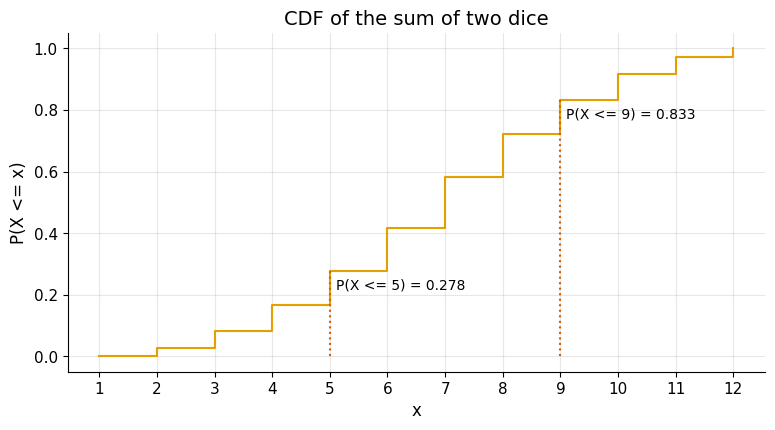

P(6 <= X <= 9) = F(9) - F(5) = 0.5556


In [3]:
cdf = np.cumsum(pmf)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.step(np.concatenate([[1], xs]), np.concatenate([[0], cdf]), where="post", color=SIM)
ax.set_xlabel("x"); ax.set_ylabel("P(X <= x)"); ax.set_title("CDF of the sum of two dice"); ax.set_xticks(np.arange(1, 13))
for q, lab in [(5, "P(X <= 5)"), (9, "P(X <= 9)")]:
    ax.plot([q, q], [0, cdf[q - 2]], color=HIGHLIGHT, linestyle=":"); ax.text(q + 0.1, cdf[q - 2] - 0.06, f"{lab} = {cdf[q - 2]:.3f}")
plt.show()
print(f"P(6 <= X <= 9) = F(9) - F(5) = {cdf[7] - cdf[3]:.4f}")
assert np.isclose(cdf[-1], 1) and np.isclose(cdf[7] - cdf[3], sum(pmf[xs == v][0] for v in (6, 7, 8, 9)))

### 7.3 Same mean, different spread
Three games all have the expected payoff 10, but very different risk: a sure 10, a fair coin between 0 and 20, and a rare big win (1 in 20 pays 200). The mean is the same; the standard deviation tells them apart.

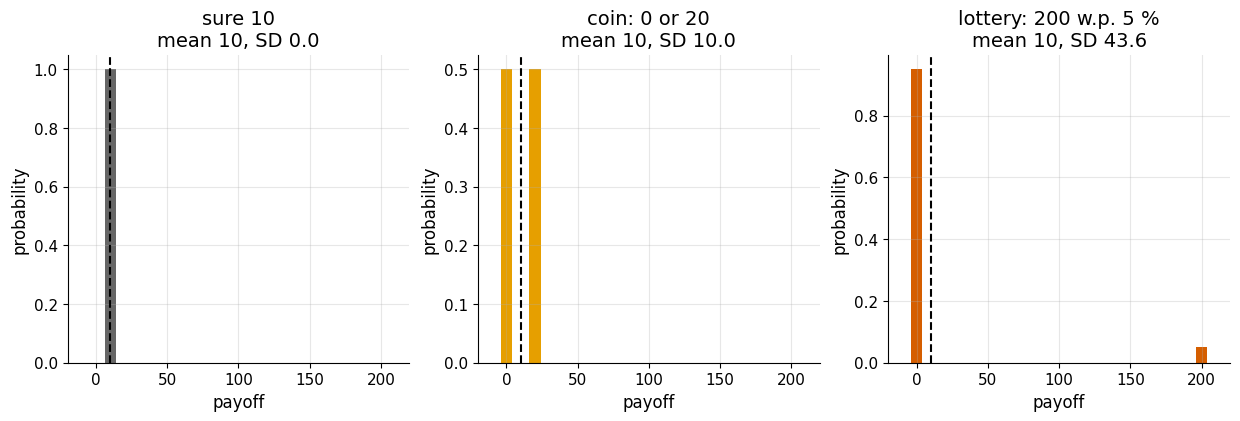

In [4]:
games = {"sure 10": ([10], [1.0]), "coin: 0 or 20": ([0, 20], [0.5, 0.5]), "lottery: 200 w.p. 5 %": ([0, 200], [0.95, 0.05])}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
for ax, (nm, (vals, pr)), c in zip(axes, games.items(), [NEUTRAL, SIM, HIGHLIGHT]):
    vals, pr = np.array(vals, float), np.array(pr); m = (vals * pr).sum(); sd = np.sqrt(((vals - m) ** 2 * pr).sum())
    ax.bar(vals, pr, width=8, color=c); ax.axvline(m, color="black", linestyle="--"); ax.set_xlim(-20, 220); ax.set_title(f"{nm}\nmean {m:.0f}, SD {sd:.1f}"); ax.set_xlabel("payoff"); ax.set_ylabel("probability")
plt.show()

### 7.4 The running average settles at the expected value
Roll the pair of dice repeatedly and track the average of the sums. It wanders at first and then locks onto 7 (this is the law of large numbers, 05_01).

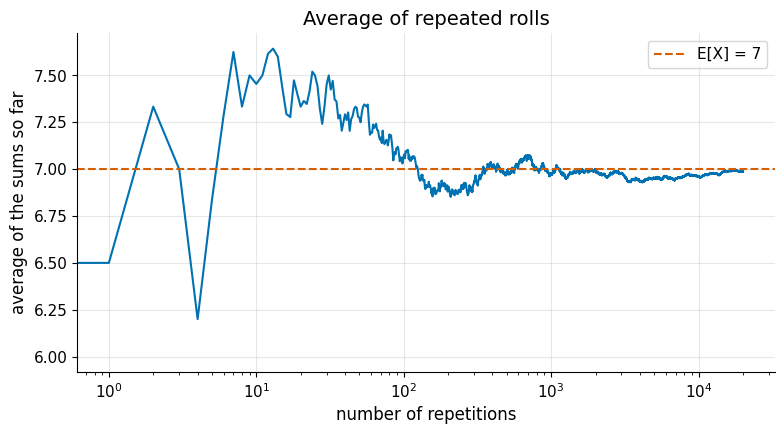

{10: np.float64(7.5), 100: np.float64(7.05), 1000: np.float64(6.976), 20000: np.float64(6.988)}


In [5]:
rolls = rng.integers(1, 7, (20_000, 2)).sum(axis=1)
running = np.cumsum(rolls) / np.arange(1, rolls.size + 1)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(running, color=MAIN); ax.axhline(7, color=HIGHLIGHT, linestyle="--", label="E[X] = 7"); ax.set_xscale("log")
ax.set_xlabel("number of repetitions"); ax.set_ylabel("average of the sums so far"); ax.set_title("Average of repeated rolls"); ax.legend()
plt.show()
print({n_: round(running[n_ - 1], 3) for n_ in (10, 100, 1000, 20000)})
assert abs(running[-1] - 7) < 0.1

## 8. 3D visuals

### 8.1 Static: two dice, each outcome coloured by its number $X=r+b$
Each bar is one of the 36 equally likely outcomes (height $1/36$) and its colour is the value of the random variable. The 6 outcomes on the anti-diagonal share the value 7, which is why that value is the most likely.

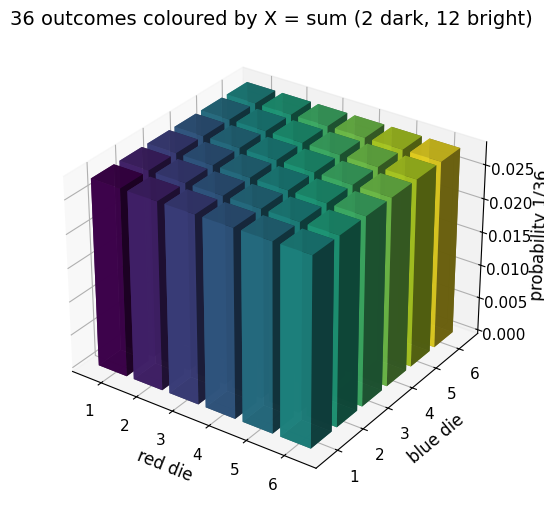

In [6]:
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
rr, bb = np.meshgrid(range(1, 7), range(1, 7), indexing="ij")
vals = (rr + bb).ravel()
cmap = plt.get_cmap("viridis")
ax.bar3d(rr.ravel() - 0.4, bb.ravel() - 0.4, 0, 0.8, 0.8, np.full(36, 1 / 36), color=cmap((vals - 2) / 10), alpha=0.9)
ax.set_xlabel("red die"); ax.set_ylabel("blue die"); ax.set_zlabel("probability 1/36"); ax.set_title("36 outcomes coloured by X = sum (2 dark, 12 bright)"); ax.view_init(elev=30, azim=-55)
plt.show()

### 8.2 Interactive Plotly version
Rotate and hover: each point shows the outcome and the value of $X$. The surface of $X=r+b$ is a tilted plane over the grid; the PMF counts how many grid points lie on each level.

In [7]:
fig = go.Figure(go.Surface(x=np.arange(1, 7), y=np.arange(1, 7), z=(rr + bb).T.astype(float), colorscale="Viridis"))
fig.update_layout(title="The random variable X(r, b) = r + b", width=700, height=520, scene=dict(xaxis_title="red die", yaxis_title="blue die", zaxis_title="X = sum"))
fig.show()

## 9. Simulation vs theory

### 9.1 PMF, mean and variance of the dice sum
Simulate 500,000 rolls and compare the observed table, mean and variance with the exact values.

In [8]:
sim = rng.integers(1, 7, (500_000, 2)).sum(axis=1)
freq = np.bincount(sim, minlength=13)[2:] / sim.size
print(pd.DataFrame({"x": xs, "exact": pmf.round(4), "simulated": freq.round(4)}).T.to_string(header=False))
print(f"mean: simulated {sim.mean():.4f} vs 7 | variance: simulated {sim.var():.4f} vs {35 / 6:.4f}")
assert np.allclose(freq, pmf, atol=0.003) and abs(sim.var() - 35 / 6) < 0.05

x          2.0000  3.0000  4.0000  5.0000  6.0000  7.0000  8.0000  9.0000  10.0000  11.0000  12.0000
exact      0.0278  0.0556  0.0833  0.1111  0.1389  0.1667  0.1389  0.1111   0.0833   0.0556   0.0278
simulated  0.0280  0.0549  0.0835  0.1114  0.1396  0.1668  0.1385  0.1109   0.0834   0.0554   0.0277
mean: simulated 6.9982 vs 7 | variance: simulated 5.8261 vs 5.8333


### 9.2 Linearity and the additivity of variance
For one die $E=3.5$, $\mathrm{Var}=35/12=2.917$. For the sum of two independent dice: mean $7$ and variance $2\times2.917=5.833$. For the *same* die counted twice ($X+X=2X$) the variance is $2^2\times2.917=11.67$, not $5.83$: independence matters for variances, not for means.

In [9]:
die = rng.integers(1, 7, 400_000); die2 = rng.integers(1, 7, 400_000)
print(f"independent sum: mean {(die + die2).mean():.3f} (7), variance {(die + die2).var():.3f} (5.833)")
print(f"same die twice : mean {(2 * die).mean():.3f} (7), variance {(2 * die).var():.3f} (11.667)")
print(f"linear change  : E[3X + 2] = {(3 * die + 2).mean():.3f} (12.5), Var(3X + 2) = {(3 * die + 2).var():.3f} (26.25)")
assert abs((die + die2).var() - 35 / 6) < 0.05 and abs((2 * die).var() - 4 * 35 / 12) < 0.1 and abs((3 * die + 2).mean() - 12.5) < 0.02

independent sum: mean 6.998 (7), variance 5.822 (5.833)
same die twice : mean 6.993 (7), variance 11.644 (11.667)
linear change  : E[3X + 2] = 12.489 (12.5), Var(3X + 2) = 26.198 (26.25)


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

`scipy.stats.rv_discrete` turns any probability table into a distribution object with `pmf`, `cdf`, `mean`, `var`, `std` and `rvs`.

In [10]:
dice_sum = stats.rv_discrete(name="dice_sum", values=(xs, pmf))
print("mean, variance, SD:", dice_sum.mean(), round(dice_sum.var(), 4), round(dice_sum.std(), 4))
print("pmf(7) =", round(dice_sum.pmf(7), 4), "| cdf(5) =", round(dice_sum.cdf(5), 4), "| P(6 <= X <= 9) =", round(dice_sum.cdf(9) - dice_sum.cdf(5), 4), "| sf(9) = P(X > 9) =", round(dice_sum.sf(9), 4))
print("quantile (smallest x with cdf >= 0.9): ppf(0.9) =", dice_sum.ppf(0.9), "| 10 random draws:", dice_sum.rvs(size=10, random_state=3))
print("expected value of a function: dice_sum.expect(lambda x: x ** 2) =", round(dice_sum.expect(lambda x: x ** 2), 4), "= Var + mean^2 =", round(35 / 6 + 49, 4))
print("by hand with NumPy: np.sum(xs * pmf) =", np.sum(xs * pmf), "| np.sum((xs - 7) ** 2 * pmf) =", round(np.sum((xs - 7) ** 2 * pmf), 4))
print("sample statistics: sim.mean(), sim.var(), sim.std() ->", round(sim.mean(), 3), round(sim.var(), 3), round(sim.std(), 3))

mean, variance, SD: 6.999999999999998 5.8333 2.4152
pmf(7) = 0.1667 | cdf(5) = 0.2778 | P(6 <= X <= 9) = 0.5556 | sf(9) = P(X > 9) = 0.1667
quantile (smallest x with cdf >= 0.9): ppf(0.9) = 10.0 | 10 random draws: [ 7  8  6  7 10 10  4  5  3  7]
expected value of a function: dice_sum.expect(lambda x: x ** 2) = 54.8333 = Var + mean^2 = 54.8333
by hand with NumPy: np.sum(xs * pmf) = 6.999999999999998 | np.sum((xs - 7) ** 2 * pmf) = 5.8333
sample statistics: sim.mean(), sim.var(), sim.std() -> 6.998 5.826 2.414


## 11. Real-world worked examples

---
### Example 1 (main): a raffle ticket

**Scenario.** A charity sells **1,000 raffle tickets at \$2 each**. One ticket wins **\$500**, two tickets win **\$100** each, ten tickets win **\$20** each, and the rest win nothing. Let $X$ be the prize of a randomly chosen ticket.

**Questions**
1. Write the **probability table** of $X$.
2. What is the **expected prize** $E[X]$, and the **expected net gain** per ticket after paying \$2?
3. What are the **variance and standard deviation** of the prize?
4. A fan buys **50 tickets**. What are the mean and SD of the total net gain, and what is the probability of coming out ahead (net gain above 0)?

### 11.1 By hand
**Q1.** $P(X=500)=0.001$, $P(X=100)=0.002$, $P(X=20)=0.010$, $P(X=0)=0.987$.

**Q2.** $E[X]=500(0.001)+100(0.002)+20(0.010)+0(0.987)=0.5+0.2+0.2=\$0.90$. Net gain per ticket $E[X-2]=0.90-2=\mathbf{-\$1.10}$ (linearity).

**Q3.** $E[X^2]=500^2(0.001)+100^2(0.002)+20^2(0.010)=250+20+4=274$. $\mathrm{Var}(X)=274-0.9^2=273.19$ and $\mathrm{SD}=\sqrt{273.19}=\$16.53$.

**Q4.** For 50 tickets (treated as independent) the total net gain has mean $50\times(-1.10)=-\$55$ and variance $50\times273.19$, so the SD is $\sqrt{50}\times16.53=\$116.9$. The distribution is very skewed (most people win nothing), so a Normal approximation is poor; we compute $P(\text{net gain}>0)$ exactly by simulation below.

In [11]:
prizes = np.array([500, 100, 20, 0]); probs_p = np.array([0.001, 0.002, 0.010, 0.987])
mean_p = np.sum(prizes * probs_p); ex2 = np.sum(prizes**2 * probs_p); var_p = ex2 - mean_p**2
print(f"Q2: E[prize] = {mean_p:.2f}, expected net gain = {mean_p - 2:.2f}")
print(f"Q3: E[X^2] = {ex2:.0f}, Var = {var_p:.2f}, SD = {np.sqrt(var_p):.2f}")
print(f"Q4: 50 tickets: mean net gain {50 * (mean_p - 2):.1f}, SD {np.sqrt(50 * var_p):.1f}")

Q2: E[prize] = 0.90, expected net gain = -1.10
Q3: E[X^2] = 274, Var = 273.19, SD = 16.53
Q4: 50 tickets: mean net gain -55.0, SD 116.9


### 11.2 In code with `scipy`, and the asserts

In [12]:
raffle = stats.rv_discrete(name="raffle", values=(prizes, probs_p))
assert np.isclose(raffle.mean(), 0.9) and np.isclose(raffle.var(), 273.19) and np.isclose(raffle.std(), 16.5283, atol=1e-3)
assert np.isclose(raffle.expect(lambda x: x - 2), -1.1)                                    # linearity: E[X - 2] = E[X] - 2
assert np.isclose(50 * (raffle.mean() - 2), -55) and abs(np.sqrt(50 * raffle.var()) - 116.9) < 0.1
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Buy 50 tickets in each of 200,000 simulated raffles and look at the distribution of the total net gain.

In [13]:
sim_rng = np.random.default_rng(31)
tickets = sim_rng.choice(prizes, size=(200_000, 50), p=probs_p)
net = tickets.sum(axis=1) - 100                              # 50 tickets cost $100
print(f"simulated: mean net {net.mean():.2f} (theory -55) | SD {net.std():.1f} (theory 116.9) | P(ahead) = {np.mean(net > 0):.4f} | P(lose everything, net = -100) = {np.mean(net == -100):.4f} (0.987^50 = {0.987 ** 50:.4f})")
print(f"quantiles of the net gain: 5% {np.percentile(net, 5):.0f}, median {np.median(net):.0f}, 95% {np.percentile(net, 95):.0f}")
assert abs(net.mean() + 55) < 1.2 and abs(net.std() - 116.9) < 2 and abs(np.mean(net == -100) - 0.987 ** 50) < 0.004

simulated: mean net -55.02 (theory -55) | SD 116.7 (theory 116.9) | P(ahead) = 0.0868 | P(lose everything, net = -100) = 0.5204 (0.987^50 = 0.5198)
quantiles of the net gain: 5% -100, median -100, 95% 120


### 11.4 Plots with the regions shaded

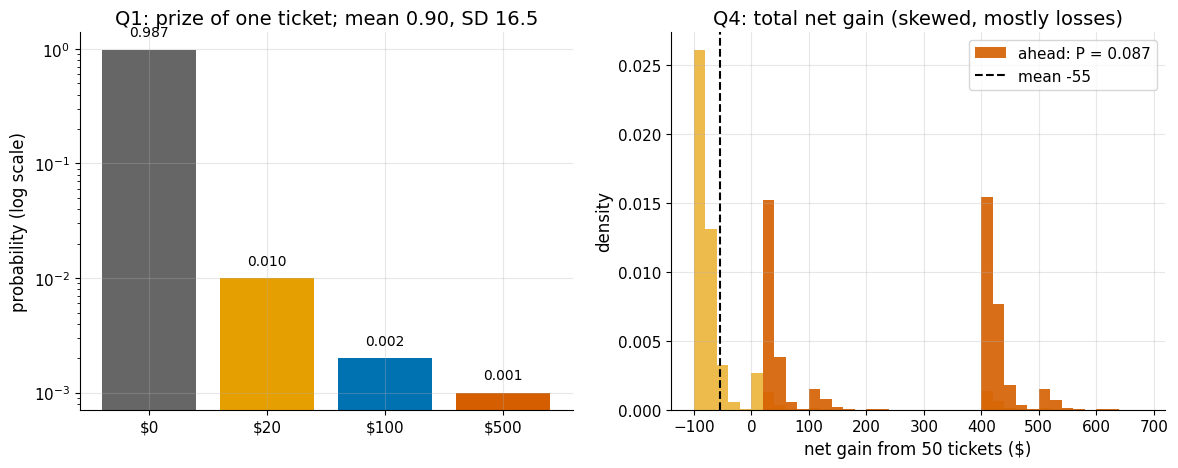

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
axes[0].bar(["$0", "$20", "$100", "$500"], probs_p[::-1], color=[NEUTRAL, SIM, MAIN, HIGHLIGHT]); axes[0].set_yscale("log"); axes[0].set_ylabel("probability (log scale)"); axes[0].set_title(f"Q1: prize of one ticket; mean {mean_p:.2f}, SD {np.sqrt(var_p):.1f}")
for i_, v_ in enumerate(probs_p[::-1]): axes[0].text(i_, v_ * 1.3, f"{v_:.3f}", ha="center")
bins = np.arange(-100, 700, 20)
axes[1].hist(net, bins=bins, color=SIM, alpha=0.7, density=True); axes[1].hist(net[net > 0], bins=bins, color=HIGHLIGHT, alpha=0.9, density=True, label=f"ahead: P = {np.mean(net > 0):.3f}")
axes[1].axvline(-55, color="black", linestyle="--", label="mean -55"); axes[1].set_xlabel("net gain from 50 tickets ($)"); axes[1].set_ylabel("density"); axes[1].set_title("Q4: total net gain (skewed, mostly losses)"); axes[1].legend()
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **A ticket loses money on average.** The expected prize is \$0.90 for a \$2 ticket, so the expected net gain is **-\$1.10 per ticket** (55 % of the price is lost to the charity). Only 1.3 % of the tickets win anything; the standard deviation of the prize, \$16.5, is much larger than its mean because of the single \$500 prize.
- **Fifty tickets make the average clearer, not the result safe.** The total net gain has mean -\$55 and SD \$116.9 (simulation: -\$55.0 and \$116.7). More than half of the buyers (**52 %**) win nothing at all, losing the full \$100, and only **8.7 %** come out ahead.
- **A Normal bell would mislead here:** with mean -55 and SD 116.9 it would claim a 32 % chance of coming out ahead, almost four times the true 8.7 %, because the distribution is strongly skewed (a few big prizes, many zeros).
- **Decision.** Buy raffle tickets only as a donation: the expected loss per ticket is certain, the possible win is a rare event, and the mean and SD alone do not describe a skewed payoff.

---
### Example 2: the dice sum (mean, variance and the sum rule)

**Scenario.** Two fair dice are rolled and $X$ is the sum. Find $E[X]$ and $\mathrm{Var}(X)$ in two ways: from the PMF table and from the rules for sums of independent variables.

### 11.6 By hand, in code and by simulation
**By hand.** One die: $\mu=3.5$, $\sigma^2=\tfrac{35}{12}=2.917$. Two independent dice: $E[X]=3.5+3.5=7$ and $\mathrm{Var}(X)=2.917+2.917=\tfrac{35}6=5.833$, so $\mathrm{SD}=2.415$. From the table (Section 7.1) the same values come out of $\sum xp(x)$ and $\sum(x-7)^2p(x)$.

rules: E[X] = 7.0, Var(X) = 5.8333 | table: E[X] = 6.999999999999998, Var(X) = 5.8333 | simulation: 6.998, 5.826
P(|X - 7| <= 1 SD): 0.6667 | P(5 <= X <= 9) = 0.6667


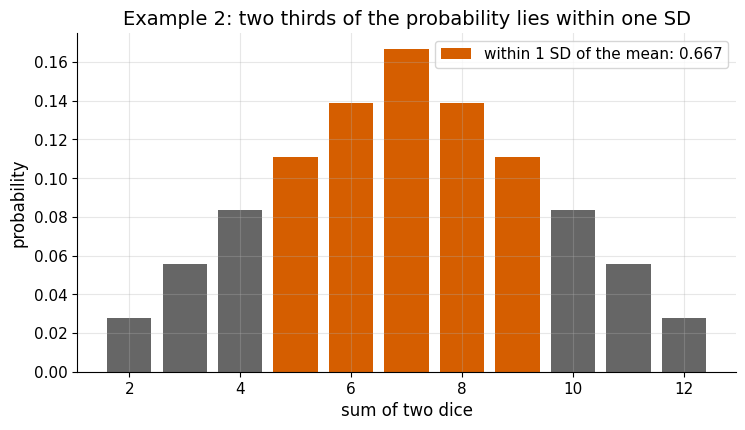

In [15]:
one = stats.randint(1, 7)
rule_mean, rule_var = 2 * one.mean(), 2 * one.var()
print(f"rules: E[X] = {rule_mean}, Var(X) = {rule_var:.4f} | table: E[X] = {mean_x}, Var(X) = {var_x:.4f} | simulation: {sim.mean():.3f}, {sim.var():.3f}")
within_one_sd = pmf[(xs >= mean_x - sd_x) & (xs <= mean_x + sd_x)].sum()
print(f"P(|X - 7| <= 1 SD): {within_one_sd:.4f} | P(5 <= X <= 9) = {pmf[(xs >= 5) & (xs <= 9)].sum():.4f}")
assert np.isclose(rule_mean, mean_x) and np.isclose(rule_var, var_x) and np.isclose(within_one_sd, 24 / 36)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
inside = (xs >= mean_x - sd_x) & (xs <= mean_x + sd_x)
ax.bar(xs[inside], pmf[inside], color=HIGHLIGHT, label=f"within 1 SD of the mean: {within_one_sd:.3f}"); ax.bar(xs[~inside], pmf[~inside], color=NEUTRAL)
ax.set_xlabel("sum of two dice"); ax.set_ylabel("probability"); ax.set_title("Example 2: two thirds of the probability lies within one SD"); ax.legend()
plt.show()

### 11.6b Interpretation and decision (Example 2)
- The two ways agree: the table and the rules both give $E[X]=7$ and $\mathrm{Var}(X)=35/6=5.83$ (SD 2.42); the simulation gives 6.998 and 5.826.
- **Two thirds of the probability (24 of 36) lies within one SD of the mean:** the sum is between 5 and 9 in 66.7 % of the rolls.
- Adding the variances of the two dice only works because they are **independent**: counting one die twice would give variance 11.7 instead of 5.8 (Section 9.2).
- **Decision.** In a game where you need a sum of 5 to 9, expect to succeed two times out of three, and expect rolls near 7 far more than extremes.

---
### Example 3: orders per hour at a small shop (expected profit and staffing)

**Scenario.** A shop receives between 0 and 5 online orders per hour with probabilities $P(0)=0.10$, $P(1)=0.25$, $P(2)=0.30$, $P(3)=0.20$, $P(4)=0.10$, $P(5)=0.05$. Each order earns **\$12** of profit; one staff member costs **\$20** per hour and can handle at most **3 orders** per hour (extra orders are lost). What is the expected number of orders, the expected hourly profit with one staff member, and the probability of lost orders?

### 11.7 By hand, in code and by simulation
**By hand.** $E[N]=0(0.10)+1(0.25)+2(0.30)+3(0.20)+4(0.10)+5(0.05)=2.10$ orders. Orders handled $=\min(N,3)$, so $E[\min(N,3)]=0.25+0.60+3(0.20+0.10+0.05)=0.25+0.60+1.05=1.90$ and the expected profit is $12(1.90)-20=\mathbf{\$2.80}$ per hour. Lost orders occur when $N\ge4$: $P=0.15$.

E[N] = 2.10, SD = 1.300 | E[orders handled] = 1.90 | E[profit per hour] = 2.80 | P(orders lost) = 0.15
simulated: mean orders 2.101, mean profit 2.796, P(lost) 0.1507, SD of profit 11.93
with two staff (capacity 6): expected profit -14.80


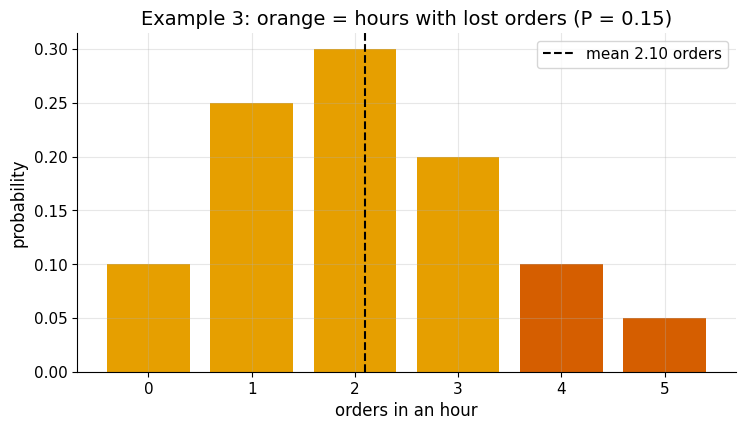

In [16]:
n_vals = np.arange(6); p_n = np.array([0.10, 0.25, 0.30, 0.20, 0.10, 0.05])
mean_n = np.sum(n_vals * p_n); sd_n = np.sqrt(np.sum((n_vals - mean_n) ** 2 * p_n))
handled = np.minimum(n_vals, 3); profit = 12 * handled - 20
e_profit = np.sum(profit * p_n); p_lost = p_n[n_vals >= 4].sum()
print(f"E[N] = {mean_n:.2f}, SD = {sd_n:.3f} | E[orders handled] = {np.sum(handled * p_n):.2f} | E[profit per hour] = {e_profit:.2f} | P(orders lost) = {p_lost:.2f}")
hourly = np.random.default_rng(14).choice(n_vals, 400_000, p=p_n)
sim_profit = 12 * np.minimum(hourly, 3) - 20
print(f"simulated: mean orders {hourly.mean():.3f}, mean profit {sim_profit.mean():.3f}, P(lost) {np.mean(hourly >= 4):.4f}, SD of profit {sim_profit.std():.2f}")
assert np.isclose(mean_n, 2.10) and np.isclose(e_profit, 2.8) and np.isclose(p_lost, 0.15) and abs(sim_profit.mean() - 2.8) < 0.05
two_staff = np.sum((12 * np.minimum(n_vals, 6) - 40) * p_n)
print(f"with two staff (capacity 6): expected profit {two_staff:.2f}")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.bar(n_vals, p_n, color=[SIM] * 4 + [HIGHLIGHT] * 2); ax.axvline(mean_n, color="black", linestyle="--", label=f"mean {mean_n:.2f} orders")
ax.set_xlabel("orders in an hour"); ax.set_ylabel("probability"); ax.set_title("Example 3: orange = hours with lost orders (P = 0.15)"); ax.legend()
plt.show()

### 11.7b Interpretation and decision (Example 3)
- The shop expects **2.10 orders per hour** (SD 1.30) but one staff member can handle only 1.90 of them on average, because in **15 %** of the hours there are 4 or 5 orders and the extra ones are lost.
- The **expected hourly profit with one staff member is \$2.80** (simulation \$2.80, with a standard deviation of \$11.9 from hour to hour).
- A second staff member would raise the handled orders to 2.10 on average (a gain of \$2.40 per hour) but cost \$20, giving an expected profit of **-\$14.80** per hour.
- **Decision.** Keep one staff member: the lost orders are worth less than the cost of a second person. Reconsider if the order rate or the profit per order rises sharply.

## 12. Where it is used

### Statistics
- **Every distribution** (Binomial, Poisson, Normal, ...) is the PMF or density of a random variable; **estimators** (the sample mean) are random variables whose mean and variance we study (Module 05).
- **Expected value and variance** are the first two **moments** (00_02); **Chebyshev and Hoeffding bounds** (05_05) turn them into guarantees.

### Data science
- **Expected value as a decision tool:** expected profit, expected cost, expected revenue per visit (Example 3); **risk** is measured by the SD or by the probability of a loss.
- **KPIs are averages of random variables:** daily orders, conversion rate, latency; their variability explains why dashboards fluctuate.

### ML and AI
- **Loss functions are expectations:** training minimises the **expected loss** $E[\ell(f(X),Y)]$, estimated by the average over a mini-batch (05_02).
- **Rewards in reinforcement learning, bandit payoffs and model scores** are random variables; the **expected value** guides decisions and the **variance** guides exploration.

## 13. Common pitfalls and misconceptions

- **Expected value is not "the most likely value" and need not be possible:** a fair die has $E[X]=3.5$.
- **The average of one game is not the expected value:** only over many repetitions do the two agree (the raffle loses \$1.10 on average, but a lucky ticket wins \$500).
- **Variances of dependent variables do not add:** $\mathrm{Var}(X+X)=4\mathrm{Var}(X)$, not $2\mathrm{Var}(X)$ (9.2).
- **$E[g(X)]\ne g(E[X])$:** $E[X^2]=274$ is far from $0.9^2$ in the raffle.
- **Quoting the variance instead of the SD:** the variance has squared units; the SD is the one to compare with the mean.
- **Treating a skewed variable as if it were symmetric:** the raffle's mean and SD alone miss that 98.7 % of tickets win nothing.
- **PMF probabilities must add to 1:** always check $\sum_xp(x)=1$ before computing a mean.

## 14. Exercises

1. A fair die is rolled and you win the number shown in dollars, but pay \$4 to play. Find the expected net gain and the probability of a positive net gain.
2. A random variable takes the values 1, 2, 3, 4 with probabilities 0.1, 0.2, 0.3, 0.4. Compute $E[X]$, $E[X^2]$, $\mathrm{Var}(X)$ and $\mathrm{SD}(X)$.
3. A game pays \$10 with probability 0.1, \$2 with probability 0.4 and nothing otherwise. What entry fee makes the game fair (expected net gain 0)? What is the SD of the payoff?
4. Three fair coins are tossed and $X$ is the number of heads. Write the PMF, $E[X]$ and $\mathrm{Var}(X)$, and check with the rule $\mathrm{Var}=3\times\frac14$ for a sum of three independent Bernoulli(1/2) variables.
5. $X$ has mean 5 and SD 2. Find the mean and SD of $Y=3X-4$ and of $Z=-X$. Why does the SD of $Z$ equal that of $X$?
6. (Harder) Roll a die repeatedly until a 6 appears; let $X$ be the number of rolls. Estimate $E[X]$ by simulation and compare it with the formula $1/p=6$ (you will meet this as the Geometric distribution in Module 01).

Solutions are at the end.

## 15. Summary table

| Quantity | Formula | Rule |
|---|---|---|
| PMF | $p(x)=P(X=x)$ | $\sum p(x)=1$ |
| CDF | $F(x)=\sum_{t\le x}p(t)$ | non-decreasing, ends at 1 |
| Mean | $E[X]=\sum xp(x)$ | $E[aX+b]=aE[X]+b$; $E[X+Y]=E[X]+E[Y]$ |
| Variance | $E[X^2]-\mu^2$ | $\mathrm{Var}(aX+b)=a^2\mathrm{Var}(X)$ |
| SD | $\sqrt{\mathrm{Var}}$ | same units as $X$ |
| Sum of independent | $\mathrm{Var}(X+Y)=\mathrm{Var}X+\mathrm{Var}Y$ | SD of the average $\sigma/\sqrt n$ |
| `scipy.stats` | `rv_discrete(values=(x, p))` | `.mean() .var() .pmf() .cdf() .rvs()` |

## Solutions

In [17]:
faces = np.arange(1, 7)
print(f"1: E[net] = {faces.mean() - 4:.2f} dollars | P(net > 0) = P(X > 4) = {np.mean(faces > 4):.4f}")
x2, p2 = np.array([1, 2, 3, 4]), np.array([0.1, 0.2, 0.3, 0.4])
m2 = np.sum(x2 * p2); e2 = np.sum(x2**2 * p2)
print(f"2: E[X] = {m2:.2f}, E[X^2] = {e2:.2f}, Var = {e2 - m2**2:.2f}, SD = {np.sqrt(e2 - m2**2):.4f}")
x3, p3 = np.array([10, 2, 0]), np.array([0.1, 0.4, 0.5]); m3 = np.sum(x3 * p3)
print(f"3: fair fee = {m3:.2f} dollars | SD of the payoff = {np.sqrt(np.sum(x3**2 * p3) - m3**2):.4f}")
x4 = np.arange(4); p4 = np.array([math.comb(3, k) for k in x4]) / 8
print(f"4: PMF {p4} | E[X] = {np.sum(x4 * p4):.2f} | Var = {np.sum(x4**2 * p4) - np.sum(x4 * p4)**2:.3f} (3 x 1/4 = {3 / 4})")
print("5: E[3X - 4] =", 3 * 5 - 4, "| SD(3X - 4) =", 3 * 2, "| E[-X] =", -5, "| SD(-X) =", 2)
first6 = (np.argmax(rng.integers(1, 7, (200_000, 60)) == 6, axis=1) + 1)
print(f"6: simulated E[X] = {first6.mean():.3f} (formula 6)")

1: E[net] = -0.50 dollars | P(net > 0) = P(X > 4) = 0.3333
2: E[X] = 3.00, E[X^2] = 10.00, Var = 1.00, SD = 1.0000
3: fair fee = 1.80 dollars | SD of the payoff = 2.8914
4: PMF [0.125 0.375 0.375 0.125] | E[X] = 1.50 | Var = 0.750 (3 x 1/4 = 0.75)
5: E[3X - 4] = 11 | SD(3X - 4) = 6 | E[-X] = -5 | SD(-X) = 2
6: simulated E[X] = 5.992 (formula 6)


**1.** Expected prize 3.5, so the expected net gain is $3.5-4=\mathbf{-\$0.50}$. The net gain is positive only for a 5 or a 6: $P=\mathbf{1/3}$.

**2.** $E[X]=0.1+0.4+0.9+1.6=\mathbf{3.0}$; $E[X^2]=0.1+0.8+2.7+6.4=\mathbf{10.0}$; $\mathrm{Var}=10-9=\mathbf{1.0}$; $\mathrm{SD}=\mathbf{1.0}$.

**3.** Expected payoff $10(0.1)+2(0.4)+0=\mathbf{\$1.80}$, the fair entry fee. $E[X^2]=100(0.1)+4(0.4)=11.6$, $\mathrm{Var}=11.6-3.24=8.36$, $\mathrm{SD}=\mathbf{\$2.89}$.

**4.** $P(X=0,1,2,3)=\tfrac18,\tfrac38,\tfrac38,\tfrac18$; $E[X]=\mathbf{1.5}$; $E[X^2]=0.375+1.5+1.125=3$, $\mathrm{Var}=3-2.25=\mathbf{0.75}=3\times\tfrac14$. ✓

**5.** $E[Y]=3(5)-4=\mathbf{11}$ and $\mathrm{SD}(Y)=3\times2=\mathbf{6}$ (the shift $-4$ does not change the spread). $E[Z]=\mathbf{-5}$ and $\mathrm{SD}(Z)=|-1|\times2=\mathbf{2}$, because $\mathrm{Var}(aX)=a^2\mathrm{Var}(X)$ and $a^2=1$ for $a=-1$: flipping the sign mirrors the distribution without changing its width.

**6.** The simulation gives 5.99, matching $1/p=6$: on average it takes 6 rolls to see the first six (Geometric distribution, Module 01).